In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle as pickle
import csv
from scipy.optimize import curve_fit

import import_ipynb
import ipynb.fs.full.ssiProjectModule as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms
from numpy import linalg as LA

import pandas as pd

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import re
from bisect import bisect

In [11]:
theta_step = 2
stim = np.arange(0,360,theta_step)
main_dir = '/home/tommaso/Documents/Carlo/'
dat_dir_out = main_dir + f'Simulated Stretch/Fix_TC_Area__vary_s/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_20240509.pkl'

# with open(dat_dir_out+title, 'rb') as rick:
#     dat_dict = pickle.load(rick)
# print(dat_dict['all_multipliers'])

In [109]:
multiplier = np.array([ 0.01 ,  0.02 ,  0.025,  0.05 ,  0.055,  0.06 ,  0.065,  0.07 ,  
                        0.075,  0.1  ,  0.125,  0.15 ,  0.175,  0.2  ,  0.225,  0.25 ,  
                        0.3  ,  0.35 ,  0.4  ,  0.45 ,  0.5  ,  0.525,  0.55 ,  0.6  ,  
                        0.625,  0.65 ,  0.7  ,  0.725,  0.75 ,  0.8  ,  0.825,  0.85 ,  
                        0.9  ,  0.95 ,  1.   ,  1.1  ,  1.2  ,  1.3  ,  1.5  ,  1.7  ,  
                        1.9  ,  2.   ,  2.25 ,  2.5  ,  2.75 ,  3    ,  3.25 ,  3.5  ,   
                        3.75 ,  4    ,  4.25 ,  4.5  ,  4.75 ,  5.   ,  7.5  ,  10.    ])

[1.00e-02 2.50e-02 5.00e-02 5.50e-02 6.00e-02 6.50e-02 7.00e-02 7.50e-02
 1.00e-01 1.25e-01 1.50e-01 1.75e-01 2.00e-01 2.25e-01 2.50e-01 3.00e-01
 3.50e-01 4.00e-01 4.50e-01 5.00e-01 5.00e-01 5.50e-01 6.00e-01 6.00e-01
 6.50e-01 7.00e-01 7.50e-01 7.50e-01 8.00e-01 8.00e-01 8.50e-01 9.00e-01
 9.00e-01 1.00e+00 1.10e+00 1.20e+00 1.30e+00 1.50e+00 1.70e+00 1.90e+00
 2.10e+00 2.30e+00 2.50e+00 2.70e+00 2.90e+00 3.10e+00 3.30e+00 3.50e+00
 3.70e+00 3.90e+00 4.10e+00 4.30e+00 4.50e+00 4.70e+00 4.90e+00 5.00e+00
 7.50e+00 1.00e+01 2.50e+01]


In [12]:
overwrite_regardless = False
file_complete = False

add_multiplier = np.array([ 0.01 ,  0.02 ,  0.025,  0.05 ,  0.055,  0.06 ,  0.065,  0.07 ,  
                        0.075,  0.1  ,  0.125,  0.15 ,  0.175,  0.2  ,  0.225,  0.25 ,  
                        0.3  ,  0.35 ,  0.4  ,  0.45 ,  0.5  ,  0.525,  0.55 ,  0.6  ,  
                        0.625,  0.65 ,  0.7  ,  0.725,  0.75 ,  0.8  ,  0.825,  0.85 ,  
                        0.9  ,  0.95 ,  1.   ,  1.1  ,  1.2  ,  1.3  ,  1.5  ,  1.7  ,  
                        1.9  ,  2.   ,  2.25 ,  2.5  ,  2.75 ,  3    ,  3.25 ,  3.5  ,   
                        3.75 ,  4    ,  4.25 ,  4.5  ,  4.75 ,  5.   ,  7.5  ,  10.    ])

selection = [1,2,3,4,5,6,7]
# selection = [7]
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509'

if overwrite_regardless:
    foundfile = False
else:
    foundfile = os.path.isfile(dat_dir_out+title+'.pkl')
    
    
if 'old_d_to_pickle' in globals(): del old_d_to_pickle
if 'new_d_to_pickle' in globals(): del new_d_to_pickle
n_quads_done=0
if foundfile:
    with open(dat_dir_out+title+'.pkl', 'rb') as rick:
        old_d_to_pickle = pickle.load(rick)
        multiplier = np.setdiff1d(np.around(add_multiplier,3), np.around(old_d_to_pickle['all_multipliers'],3))
        if not multiplier.size and file_complete:
            print('There are no NEW multipliers! ')
            size: sys.exit()
        if not file_complete:
            multiplier = np.around(np.copy(add_multiplier),3)
            new_d_to_pickle = old_d_to_pickle.copy()
        n_quads_done = len(new_d_to_pickle['all_ssis'])
        print('dd',n_quads_done)
else:
    multiplier = np.around(np.copy(add_multiplier),3)
    print('Found file: ', foundfile)
    new_d_to_pickle = {'all_multipliers':multiplier}

num_processes = 2

n_quads_calculated = 0
for j, experiment_number in enumerate(selection):
    print(datetime.now())
    experiment_name = f'Exp{experiment_number}'

    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
    quad_combos = datanfits['quadruplet_combos']

    print('Computing experiment ',experiment_number)
    for i, el in enumerate(quad_combos):
        n_quads_calculated+=1
        if n_quads_calculated<=n_quads_done:
            continue

        print(len(quad_combos)-i, 'quadruplets remaining...', end = '\n')
        aux_mat = np.array([])
        quad_pars = datanfits['ftvm_fit_parameters'][el,:]
#         maxTC = np.max(np.array([ssiMod.FTVM(stim, *pars) for pars in quad_pars]), axis = 1)
        for idx, x in enumerate(multiplier):
            aux_pars = np.copy(quad_pars)
            aux_pars[:,2] *= x
            aux_mat = np.concatenate((aux_mat, np.array([aux_pars]))) if aux_mat.size else np.array([aux_pars])
        #use parameters to obtain TCs - these will have their original maxima, to be renormalized
        quad_tc = np.array([[ssiMod.FTVM(stim, *p) for p in quad_p] for quad_p in aux_mat])

        
        with Pool(processes=8) as pool:  # Define the number of processes
##             # Define a partial function to handle arguments
##             PARTIAL_PROCESS_JITTERS = partial(SSI, stim=stim)
            results1 = np.squeeze(np.array(list(tqdm(pool.imap(ssiMod.MC_SSI, quad_tc[:20])))))
    
        with Pool(processes=4) as pool:  # Define the number of processes
            results2 = np.squeeze(np.array(list(tqdm(pool.imap(ssiMod.MC_SSI, quad_tc[20:40])))))

        with Pool(processes=2) as pool:  # Define the number of processes
            results3 = np.squeeze(np.array(list(tqdm(pool.imap(ssiMod.MC_SSI, quad_tc[40:])))))
            
        results = np.concatenate((results1, results2, results3))
        
        new_d_to_pickle['all_quad_pars'] = np.concatenate((new_d_to_pickle['all_quad_pars'], np.array([aux_mat]))) \
                                       if 'all_quad_pars' in new_d_to_pickle.keys() else np.array([aux_mat])

        new_d_to_pickle['all_quad_tc'] = np.concatenate((new_d_to_pickle['all_quad_tc'], np.array([quad_tc]))) \
                                       if 'all_quad_tc' in new_d_to_pickle.keys() else np.array([quad_tc])

        new_d_to_pickle['all_ssis'] = np.concatenate((new_d_to_pickle['all_ssis'], np.array([results]))) \
                                       if 'all_ssis' in new_d_to_pickle.keys() else np.array([results])
        
        if not foundfile or not file_complete:
            with open(dat_dir_out+title+'.pkl', 'wb') as rick:
                pickle.dump(new_d_to_pickle, rick)
        
        else:
            with open(dat_dir_out+title+'_add_multipliers.pkl', 'wb') as rick:
                pickle.dump(new_d_to_pickle, rick)            
            
                
if foundfile and file_complete:
    
    with open(dat_dir_out+title+'.pkl', 'rb') as rick:
        data_dict = pickle.load(rick)

    with open(dat_dir_out+title+'add_multipliers.pkl', 'rb') as rick:
        data_dict_add = pickle.load(rick)

    add_multiplier = data_dict_add['all_multipliers']
    multiplier = data_dict['all_multipliers']

    ssis = data_dict['all_ssis']
    all_quad_pars = data_dict['all_quad_pars']

    ssis_add = data_dict_add['all_ssis']
    all_quad_pars_add = data_dict_add['all_quad_pars']

    tcs = data_dict['all_quad_tc']
    tcs_add = data_dict_add['all_quad_tc']

    print(add_multiplier.shape)
    print(multiplier.shape)


    for i,el in enumerate(np.setdiff1d(add_multiplier, multiplier)):
        idx = bisect(multiplier,el)
        multiplier = np.insert(multiplier, idx,el)
        ssis = np.insert(ssis, idx, ssis_add[:,i,:], axis = 1)
        all_quad_pars = np.insert(all_quad_pars, idx, all_quad_pars_add[:,i,:,:], axis = 1)

    with open(dat_dir_out+title+'.pkl', 'wb') as rick:
        pickle.dump(data_dict, rick)

Found file:  False
2024-05-09 10:56:25.563609
Computing experiment  1
120 quadruplets remaining...


0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

119 quadruplets remaining...


...

0it [00:00, ?it/s]

1 quadruplets remaining...


0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

[1.0e-02 2.5e-02 5.0e-02 7.5e-02 1.0e-01 2.5e-01 5.0e-01 7.5e-01 1.0e+00
 2.5e+00 5.0e+00 7.5e+00 1.0e+01 2.5e+01 5.0e+01]


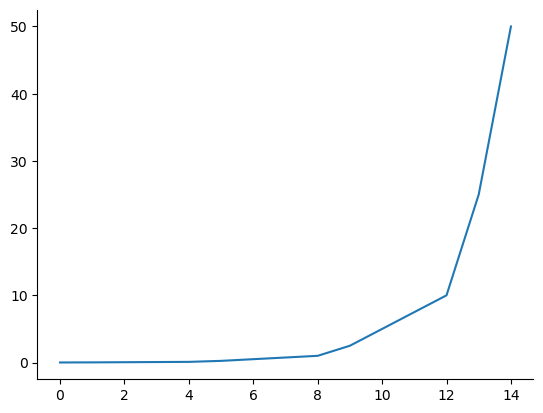

In [91]:
multiplier = np.sort(np.around(np.unique(np.concatenate((np.logspace(-2,1, 4, endpoint = True), \
                                                            5*np.logspace(-2,2, 4, endpoint = False),\
                                                            2.5*np.logspace(-2,2, 4, endpoint = False),\
                                                            7.5*np.logspace(-2,1, 3, endpoint = False) ))),5))
print(multiplier)
plt.plot(range(len(multiplier)), multiplier)

In [3]:
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}.pkl'


(648, 55, 4, 5)
Stretch_BioQuads_multiplied_w_mean_g__theta_step=2.pkl
Stretch_BioQuads_multiplied_w_mean_g__theta_step=2


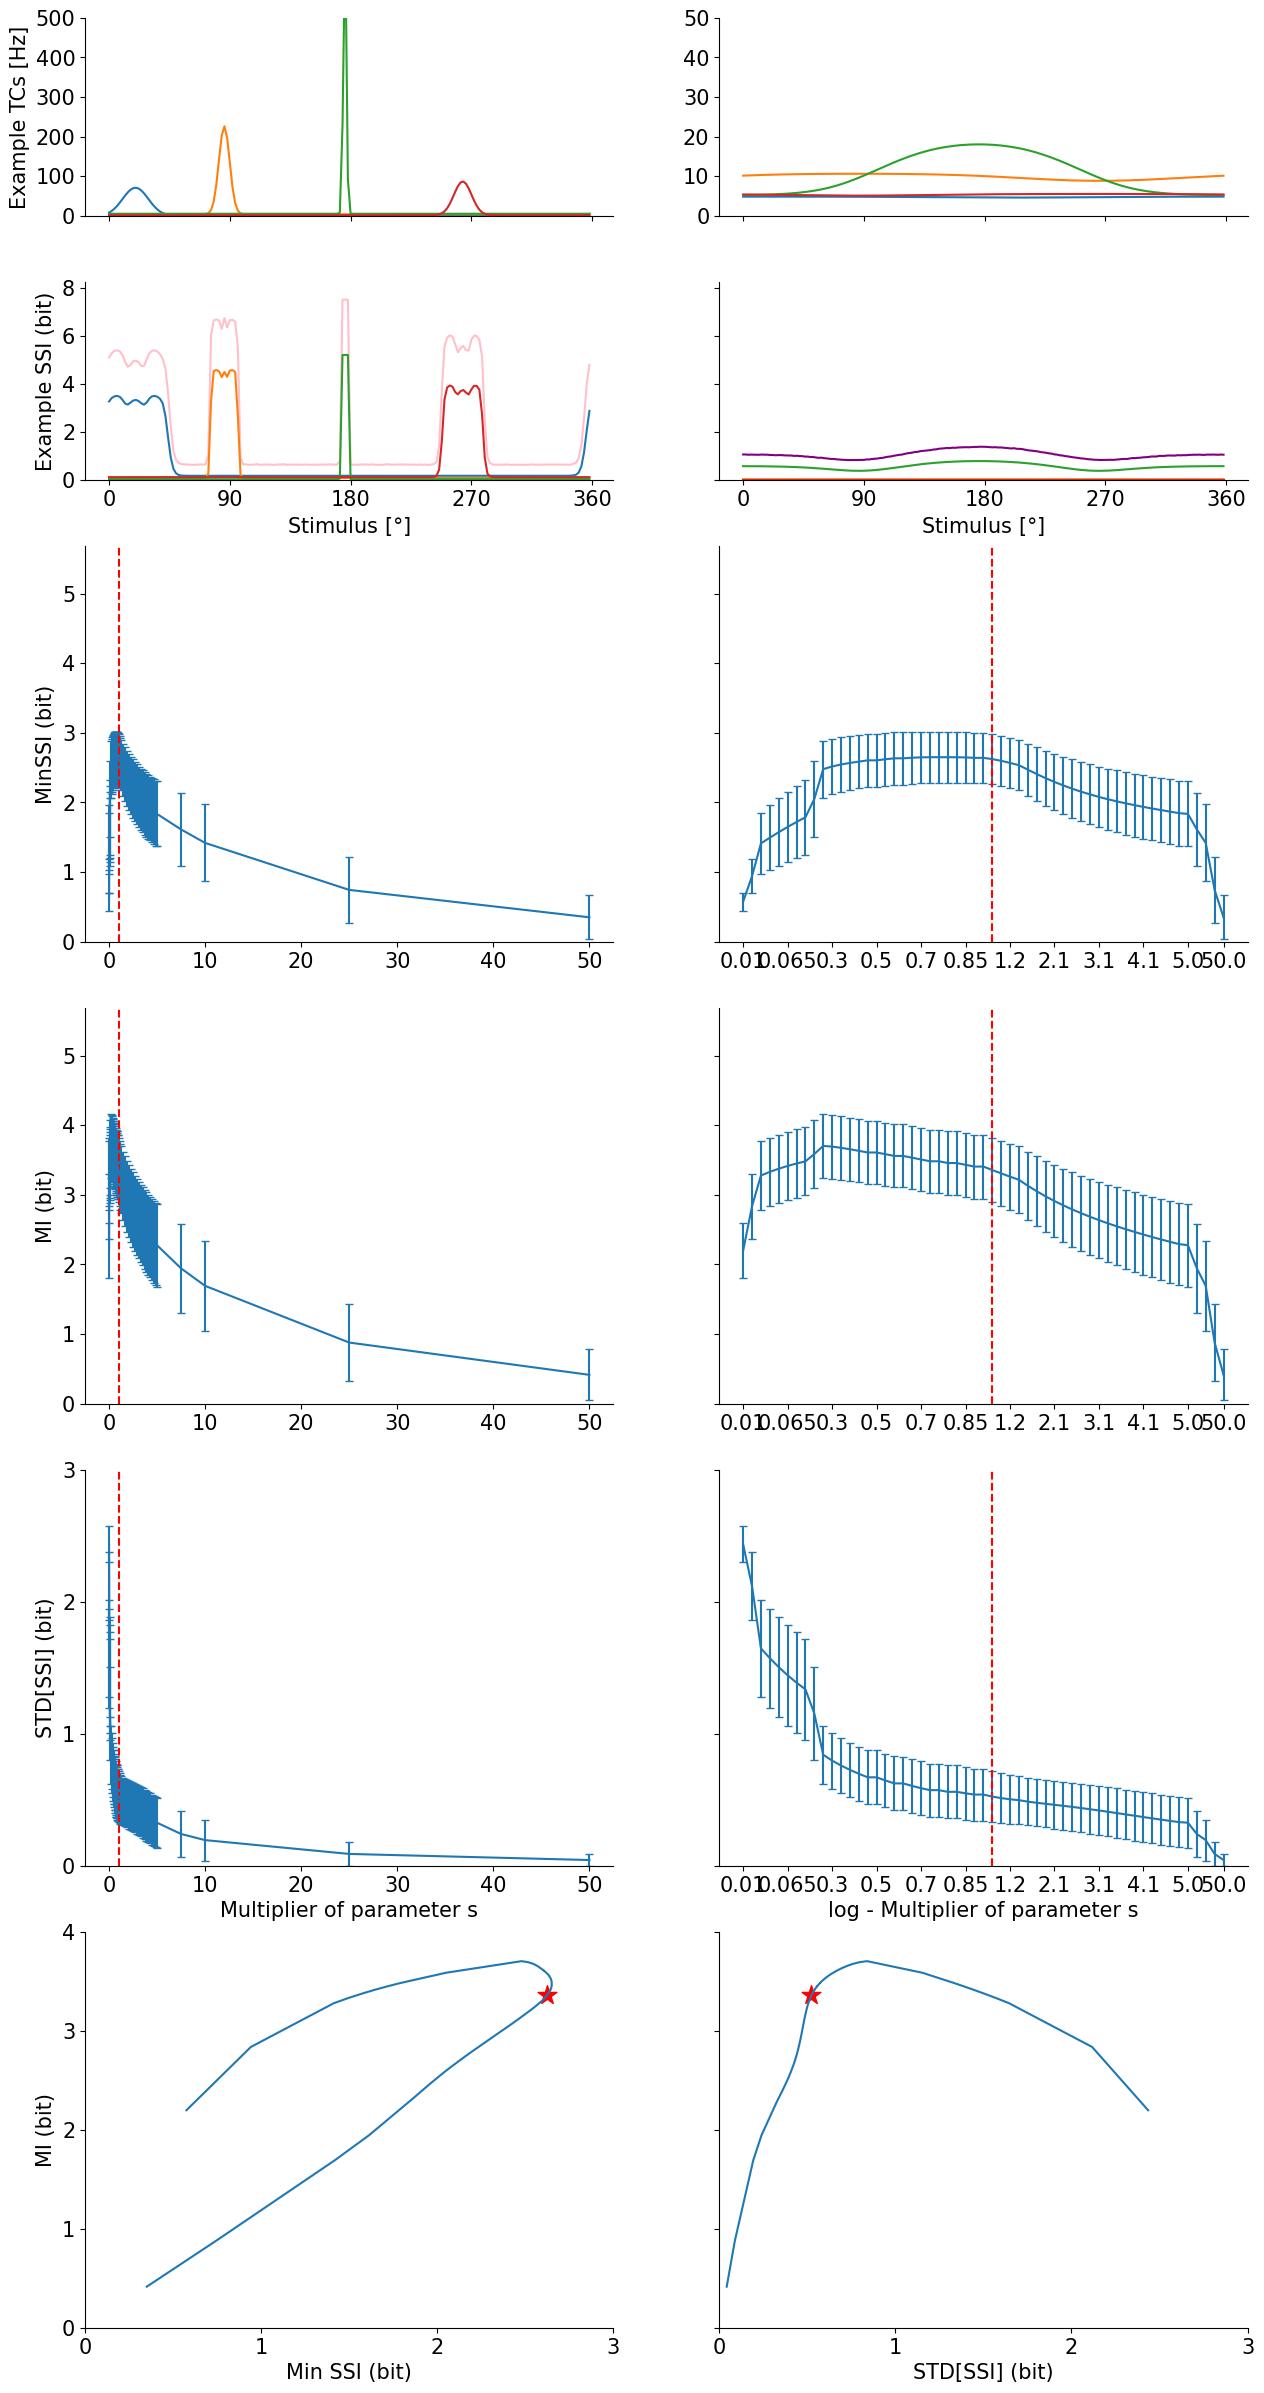

In [53]:
import re
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# inset_ax = inset_axes(parent_axes,
#                     width="30%", # width = 30% of parent_bbox
#                     height=1., # height : 1 inch
#                     loc=3)


bio_color = 'red'

main_dir = '/home/tommaso/Documents/Carlo/'
dat_dir_out = main_dir + f'Simulated Stretch/Fix_TC_Area__vary_s/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}.pkl'
with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
    


bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
maxMI_idx = np.argmax(data_dict['MI'])
maxMin_idx = np.argmax(data_dict['minSSI'])

fig = plt.figure(figsize = (15,30))
gs = gridspec.GridSpec(6,2, height_ratios = (1,1,2,2,2,2))

all_quad_pars = data_dict['all_quad_pars']
print(all_quad_pars.shape)
comparison_quad_pars_narrow = all_quad_pars[100, 0, :,:]
comparison_quad_pars_wide = all_quad_pars[100, len(data_dict['all_multipliers'])-1, :,:]
narrow_tcs = np.array([ssiMod.FTVM(stim, *quad) for quad in comparison_quad_pars_narrow])/1.6
wide_tcs = np.array([ssiMod.FTVM(stim, *quad) for quad in comparison_quad_pars_wide])/1.6
narrow_ssi = data_dict['all_ssis'][100,0]
wide_ssi = data_dict['all_ssis'][100,-1]

ax_tc_narrow = fig.add_subplot(gs[0,0])
ax_tc_wide = fig.add_subplot(gs[0,1])
ax_ssi_narrow = fig.add_subplot(gs[1,0])
ax_ssi_wide = fig.add_subplot(gs[1,1])

ax_tc_narrow.tick_params('both', labelsize = 15)
ax_tc_wide.tick_params('both', labelsize = 15)
ax_ssi_narrow.tick_params('both', labelsize = 15)
ax_ssi_wide.tick_params('both', labelsize = 15)



ax_tc_narrow.plot(stim, narrow_tcs.T)
ax_tc_wide.plot(stim, wide_tcs.T)
ax_ssi_narrow.plot(stim, narrow_ssi, color = 'pink')
ax_ssi_narrow.plot(stim, ssiMod.GET_SSI_LOOP(narrow_tcs).T)
ax_ssi_wide.plot(stim, ssiMod.GET_SSI_LOOP(wide_tcs).T,)
ax_ssi_wide.plot(stim, wide_ssi, color = 'purple')
ax_ssi_narrow.set_ylim(0,np.log2(180)*1.1)
ax_ssi_wide.set_ylim(0,np.log2(180)*1.1)


ax = fig.add_subplot(gs[2,1])
ax1 = fig.add_subplot(gs[2,0])
ax2 = fig.add_subplot(gs[3,1])
ax3 = fig.add_subplot(gs[3,0])

ax4 = fig.add_subplot(gs[4,0])
ax5 = fig.add_subplot(gs[4,1])

ax6 = fig.add_subplot(gs[5,0])
ax7 = fig.add_subplot(gs[5,1])

ax.set_ylim(0,1.1*np.log2(36))
ax1.set_ylim(0,1.1*np.log2(36))
ax2.set_ylim(0,1.1*np.log2(36))
ax3.set_ylim(0,1.1*np.log2(36))

ax.set_yticklabels([])
# ax1.set_yticklabels(np.arange(0,5.6,0.5))
ax2.set_yticklabels([])

ax.tick_params('both', labelsize = 15)
ax1.tick_params('both', labelsize = 15)
ax2.tick_params('both', labelsize = 15)
ax3.tick_params('both', labelsize = 15)
ax4.tick_params('both', labelsize = 15)
ax5.tick_params('both', labelsize = 15)
ax6.tick_params('both', labelsize = 15)
ax7.tick_params('both', labelsize = 15)

x = data_dict['all_multipliers']
# data_dict['minSSI']
y = data_dict['minSSI']
y_err = data_dict['all_ssis'].min(axis = 2).std(axis = 0)

s = data_dict['all_ssis'].std(axis = 2).mean(axis=0)
s_err = data_dict['all_ssis'].std(axis = 2).std(axis=0)

x = np.arange(0, len(y),1)
ax.errorbar(x,y, yerr=y_err, capsize = 3)


ax_tc_narrow.set_ylim(0,250)
ax_tc_wide.set_ylim(0,50)


ax_tc_narrow.set_xticks(np.arange(0,361,90))
ax_tc_narrow.set_xticklabels([])
ax_ssi_narrow.set_xticks(np.arange(0,361,90))

ax_tc_wide.set_xticks(np.arange(0,361,90))
ax_tc_wide.set_xticklabels([])
ax_ssi_wide.set_xticks(np.arange(0,361,90))

ax_tc_narrow.set_yticks(np.arange(0,501,100))
ax_tc_wide.set_yticks(np.arange(0,51,10))
ax_tc_wide.set_yticklabels(np.arange(0,51,10))

ax_ssi_narrow.set_yticks(np.arange(0,8.1,2))
ax_ssi_wide.set_yticks(np.arange(0,8.1, 2))
ax_ssi_wide.set_yticklabels([])

ax_tc_narrow.set_ylabel('Example TCs [Hz]', size = 15)
ax_ssi_narrow.set_ylabel('Example SSI (bit)', size = 15)
ax_ssi_narrow.set_xlabel(r'Stimulus [$\degree$]', size = 15)
ax_ssi_wide.set_xlabel(r'Stimulus [$\degree$]', size = 15)

# ax.set_xlim(-0.1, 1.5)
xtick_idx = np.append(np.arange(0,len(data_dict['all_multipliers']),5),len(data_dict['all_multipliers'])-1)
ax.set_xticks(xtick_idx)
ax.set_xticklabels(np.around(data_dict['all_multipliers'][xtick_idx],3))
ax2.set_xticks(xtick_idx)
ax2.set_xticklabels(np.around(data_dict['all_multipliers'][xtick_idx],3))


ax1.errorbar(data_dict['all_multipliers'], y, yerr=y_err, capsize = 3)
ax1.axvline(1., color = bio_color, linestyle = '--')


ax1.set_ylabel('MinSSI (bit)', size = 15)
ax.axvline(x[np.where(data_dict['all_multipliers']==1.)[0]], color = bio_color, linestyle = '--')

z = data_dict['MI']
z_err = data_dict['all_ssis'].mean(axis = 2).std(axis = 0)
# ax2.set_title(r'$\Delta$s vs MI')
# ax3.set_title(r'$\Delta$s vs MI')

x = np.arange(0, len(y),1)
ax2.errorbar(x,z, yerr=z_err, capsize = 3)
# ax.set_xlim(-0.1, 1.5)

ax3.set_ylabel('MI (bit)', size = 15)
ax2.axvline(x[data_dict['all_multipliers']==1.], color = bio_color, linestyle = '--')
ax3.errorbar(data_dict['all_multipliers'], z, yerr=z_err, capsize = 3)
ax3.axvline(1., color = bio_color, linestyle = '--')

ax4.set_ylim(0,3)
ax5.set_ylim(0,3)


ax4.set_ylabel('STD[SSI] (bit)', size = 15)
ax4.errorbar(data_dict['all_multipliers'], s, yerr = s_err, capsize = 3)
ax5.errorbar(x, s, yerr = s_err, capsize = 3)

ax4.axvline(1., color = bio_color, linestyle = '--')
ax5.axvline(x[data_dict['all_multipliers']==1.], color = bio_color, linestyle = '--')

ax5.set_xlabel(r'log - Multiplier of parameter s', size = 15)
ax4.set_xlabel(r'Multiplier of parameter s', size = 15)

ax5.set_xticks(xtick_idx)
ax5.set_xticklabels(np.around(data_dict['all_multipliers'][xtick_idx],3))
ax4.set_yticks(np.arange(0,3.1,1))
ax5.set_yticks(np.arange(0,3.1,1))
ax5.set_yticklabels([])
# ax6.errorbar(y, z, xerr=y_err, yerr=z_err, capsize = 3, alpha = 0.6)
# ax7.errorbar(s,z, xerr=s_err, yerr=z_err, capsize = 3, alpha = 0.6)

ax6.plot(y,z)
ax7.plot(s,z)

ax6.set_ylabel('MI (bit)', size = 15)
ax6.set_xlabel('Min SSI (bit)', size = 15)
ax7.set_xlabel('STD[SSI] (bit)', size = 15)
ax6.set_xlim(0,3)
ax6.set_ylim(0,4)
ax6.set_xticks(np.arange(0,3.1,1))
ax6.set_yticks(np.arange(0,4.1,1))
ax7.set_xticks(np.arange(0,3.1,1))
ax7.set_yticks(np.arange(0,4.1,1))
ax7.set_yticklabels([])
ax7.set_xlim(0,3)
ax7.set_ylim(0,4)
ax6.scatter(y[bio_idx], z[bio_idx], s=200, marker = '*',color = 'red')
ax7.scatter(s[bio_idx], z[bio_idx], s=200, marker = '*',color = 'red')
print(title)
string = re.findall(r'.+(?=[\.])', title)[0]
print(string)
# plt.savefig(dat_dir_out+string+'.pdf', bbox_inches='tight')

In [23]:
print(data_dict['all_multipliers'])

(15,)


In [85]:
main_dir = '/home/tommaso/Documents/Carlo/'
dat_dir_out = main_dir + f'Simulated Stretch/Fix_TC_Area__vary_s/'
# title = 'Stretch_BioQuads_multiplied_w_mean_g.pkl'
title = 'Stretch_BioQuads_multiplied_w_mean_g__theta_step=2.pkl'

with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)

494


([<matplotlib.axis.XTick at 0x789fad1eb160>,
 [Text(0, 0, '0.01'),
  Text(10, 0, '0.3'),
  Text(20, 0, '0.7'),
  Text(30, 0, '1.2'),
  Text(40, 0, '3.1'),
  Text(50, 0, '5.0')])

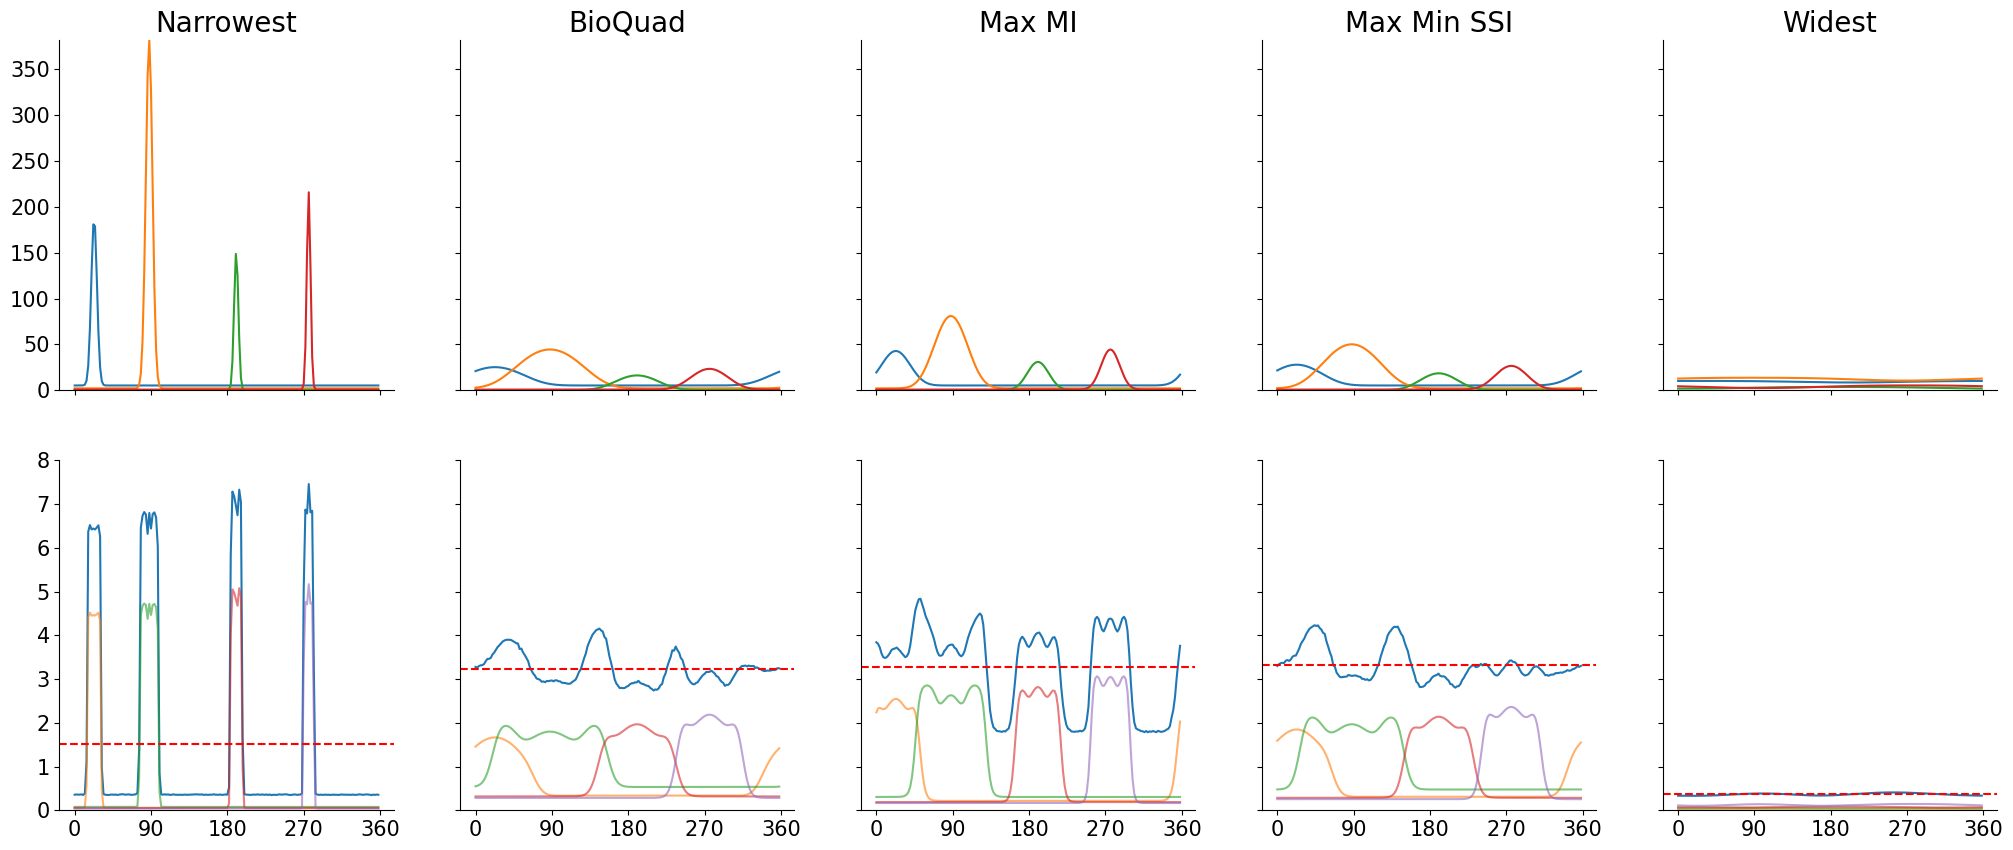

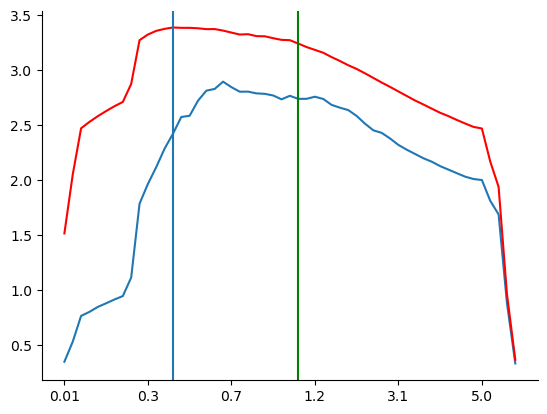

In [86]:
stim = np.arange(0,360,2)
first_idx = 0
last_idx = -1
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
maxMI_idx = np.argmax(data_dict['MI'])
maxMin_idx = np.argmax(data_dict['minSSI'])
evolution_idxs =  np.array([first_idx, bio_idx, maxMI_idx, maxMin_idx, last_idx], order='A')
evolution_titles = ['Narrowest', 'BioQuad', 'Max MI', 'Max Min SSI', 'Widest']
# np.random.seed(15)
rndm_quad = np.random.choice(range(648))
rndm_quad = 494
# rndm_quad +=1
print(rndm_quad)


fig = plt.figure(figsize = (25, 10))
gs = gridspec.GridSpec(2, len(evolution_idxs))
tc_max = -1

all_tcs = np.array([[ssiMod.FTVM(stim, *quad) for quad in data_dict['all_quad_pars'][rndm_quad, el]] for el in evolution_idxs])

for idx, el in enumerate(evolution_idxs):
    ax_tc = fig.add_subplot(gs[0, idx])
    ax_ssi = fig.add_subplot(gs[1, idx])
    
    ax_tc.set_xticks(np.arange(0,361,90))
    ax_ssi.set_xticks(np.arange(0,361,90))
    ax_tc.set_xticklabels([])
    
    ax_tc.tick_params('both', labelsize = 15)
    ax_ssi.tick_params('both', labelsize = 15)
    if idx>0:
        ax_tc.set_yticklabels([])
        ax_ssi.set_yticklabels([])
        
    ax_tc.set_title(evolution_titles[idx], size = 20)    
    ax_ssi.set_ylim(0,8)
    ax_tc.set_ylim(0,np.max(all_tcs))
    
    ax_tc.plot(stim, all_tcs[idx].T)
    ssis = ssiMod.GET_SSI_LOOP(all_tcs[idx])
    
    ax_ssi.plot(stim, data_dict['all_ssis'][rndm_quad, el])
    ax_ssi.plot(stim, ssis.T, alpha = 0.6)
    ax_ssi.axhline(data_dict['all_ssis'][rndm_quad, el].mean(), linestyle = 'dashed', color = 'red')
plt.figure()
plt.plot(np.arange(len(data_dict['all_multipliers'])), data_dict['all_ssis'][rndm_quad].min(axis=1))
plt.plot(np.arange(len(data_dict['all_multipliers'])), data_dict['all_ssis'][rndm_quad].mean(axis=1), color = 'red')

plt.axvline(np.arange(len(data_dict['all_multipliers']))[data_dict['all_ssis'][rndm_quad].mean(axis=1).argmax()])
plt.axvline(np.arange(len(data_dict['all_multipliers']))[bio_idx], color='green')
plt.xticks(np.arange(len(data_dict['all_multipliers']))[::10], np.around(data_dict['all_multipliers'][::10],3))
# plt.savefig(main_dir+f'Quad_NB_{rndm_quad}.pdf', bbox_inches = 'tight')

In [ ]:
multiplier = np.sort(np.around(np.unique(np.concatenate((np.logspace(-2,2, 5, endpoint = True), \
                                                            5*np.logspace(-2,2, 4, endpoint = False),\
                                                            2.5*np.logspace(-2,1, 3, endpoint = False),\
                                                            7.5*np.logspace(-2,1, 3, endpoint = False) ))),5))
print(multiplier[0:10])

In [88]:
main_dir = '/home/tommaso/Documents/Carlo/'
dat_dir_out = main_dir + f'Simulated Stretch/Fix_TC_Area__vary_s/'
title = 'Stretch_BioQuads_multiplied_w_mean_g__theta_step=2.pkl'
with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)

rndm_quad = 442

delta_stim1 = 1
delta_stim5 = 2
delta_stim10 = 5

stim10 = np.arange(0,360,delta_stim10)
stim5 = np.arange(0,360,delta_stim5)
stim1 = np.arange(0,360,delta_stim1)

multiplier = np.sort(np.around(np.unique(np.concatenate((np.logspace(-2,2, 5, endpoint = True), \
                                                            5*np.logspace(-2,2, 4, endpoint = False),\
                                                            2.5*np.logspace(-2,1, 3, endpoint = False),\
                                                            7.5*np.logspace(-2,1, 3, endpoint = False) ))),5))

multiplier = multiplier[:10]

# all_tcs10 = np.array([[ssiMod.FTVM(stim10, *el) for el in quad] for quad in data_dict['all_quad_pars'][rndm_quad][:10]])
# all_tcs5 = np.array([[ssiMod.FTVM(stim5, *el) for el in quad] for quad in data_dict['all_quad_pars'][rndm_quad][:10]])
# all_tcs1 = np.array([[ssiMod.FTVM(stim1, *el) for el in quad] for quad in data_dict['all_quad_pars'][rndm_quad][:10]])

# # all_ssi10 = data_dict['all_ssis'][rndm_quad]
# all_ssi10 = np.array([ssiMod.MC_SSI(quad_tc) for quad_tc in tqdm(all_tcs10)])
# all_ssi5 = np.array([ssiMod.MC_SSI(quad_tc) for quad_tc in tqdm(all_tcs5)])
# all_ssi1 = np.array([ssiMod.MC_SSI(quad_tc) for quad_tc in tqdm(all_tcs1)])



plt.figure()
plt.plot(np.log10(multiplier), all_ssi1.mean(axis=1), color = 'red', label = f'{delta_stim1}deg')
plt.plot(np.log10(multiplier), all_ssi5.mean(axis=1), color = 'green', label = f'{delta_stim5}deg')
plt.plot(np.log10(multiplier), all_ssi10.mean(axis=1), color = 'blue', label = f'{delta_stim10}deg')
plt.tick_params('both', labelsize = 15)
plt.ylabel('Mutual Info (bit)', size = 15)
plt.xlabel(r'$Log_2-multiplier$', size = 15)
plt.xticks()
plt.ylim(0,np.log2(len(stim10)))
plt.title('Stretch vs MI', size = 20)
plt.axvline(0, color = 'black', linestyle = 'dotted')
plt.text(-1,1, 'BioQuad', size = 15)
plt.legend(handlelength = 0, labelcolor = 'linecolor', frameon =  0, fontsize = 15)
# plt.savefig(main_dir+f'mult vs MI_quad={rndm_quad}.pdf', bbox_inches = 'tight')

plt.figure()
plt.plot(np.log10(multiplier), all_ssi1.min(axis=1), color = 'red', label = f'{delta_stim1}deg')
plt.plot(np.log10(multiplier), all_ssi5.min(axis=1), color = 'green', label = f'{delta_stim5}deg')
plt.plot(np.log10(multiplier), all_ssi10.min(axis=1), color = 'blue', label = f'{delta_stim10}deg')
plt.tick_params('both', labelsize = 15)
plt.ylabel('Min SSI (bit)', size = 15)
plt.xlabel(r'$Log_2-multiplier$', size = 15)
# plt.xticks()
plt.axvline(0, color = 'black', linestyle = 'dotted')
plt.ylim(0,np.log2(len(stim10)))
plt.text(-1,4, 'BioQuad', size = 15)
plt.title('Stretch vs MinSSI', size = 20)
plt.legend(handlelength = 0, labelcolor = 'linecolor', frameon =  0, fontsize = 15)
# plt.savefig(main_dir+f'mult vs MinSSI_quad={rndm_quad}.pdf', bbox_inches = 'tight')

plt.figure()
plt.plot(np.log10(multiplier), all_ssi1.max(axis=1), color = 'red', label = f'{delta_stim1}deg')
plt.plot(np.log10(multiplier), all_ssi5.max(axis=1), color = 'green', label = f'{delta_stim5}deg')
plt.plot(np.log10(multiplier), all_ssi10.max(axis=1), color = 'blue', label = f'{delta_stim10}deg')
plt.tick_params('both', labelsize = 15)
plt.ylabel('Max SSI (bit)', size = 15)
plt.xlabel(r'$Log_2-multiplier$', size = 15)
# plt.xticks()
plt.ylim(0, 9)
plt.axvline(0, color = 'black', linestyle = 'dotted')
plt.text(-1,1, 'BioQuad', size = 15)
plt.title('Stretch vs MI', size = 20)
plt.legend(handlelength = 0, labelcolor = 'linecolor', frameon =  0, fontsize = 15)

plt.axhline(np.log2(len(stim1)), linestyle = 'dashed', dashes = (5,10),color = 'red')
plt.axhline(np.log2(len(stim5)), linestyle = 'dashed', dashes = (5,10), color = 'green')
plt.axhline(np.log2(len(stim10)), linestyle = 'dashed', dashes = (5,10), color = 'blue')
# plt.savefig(main_dir+f'mult vs MaxSSI_quad={rndm_quad}.pdf', bbox_inches = 'tight')

NameError: name 'all_ssi1' is not defined

<Figure size 640x480 with 0 Axes>

In [ ]:
gs = gridspec.GridSpec(2,3)
for idx, ssi in enumerate(all_ssi5):
    if idx == bio_idx:
        color = 'green'
    elif idx == maxMin_idx:
        color = 'gold'
    elif idx == maxMI_idx:
        color = 'magenta'
    else:
        color = 'tab:blue'
    
    fig = plt.figure(figsize = (15,5))
    ax = fig.add_subplot(gs[0,0])
    ax1 = fig.add_subplot(gs[0,1])
    ax2 = fig.add_subplot(gs[0,2])
    
    ax_tc = fig.add_subplot(gs[1,0])
    ax1_tc = fig.add_subplot(gs[1,1])
    ax2_tc = fig.add_subplot(gs[1,2])
    
    ax.set_ylim(0,9)
    ax1.set_ylim(0,9)
    ax2.set_ylim(0,9)
#     ax_tc.set_ylim(bottom = 0)
#     ax1_tc.set_ylim(bottom = 0)
#     ax2_tc.set_ylim(bottom = 0)

    
    ax.plot(stim1, all_ssi1[idx], color = color)
    ax.axhline(np.log2(len(stim1)), linestyle = 'dashed', color = 'black')
    ax.axhline(np.mean(all_ssi1[idx]), linestyle = 'dotted', color = 'red')
    ax.axhline(np.min(all_ssi1[idx]), linestyle = 'dashed', color = 'blue')
    ax.set_xticks(np.arange(0,361,90))
    ax.set_xticklabels([])
    
    ax_tc.plot(stim1, all_tcs1[idx].T)
    ax1_tc.plot(stim5, all_tcs5[idx].T)
    ax2_tc.plot(stim10, all_tcs10[idx].T)
    
    
    ax1.plot(stim5, all_ssi5[idx], color = color)
    ax1.axhline(np.log2(len(stim5)), linestyle = 'dashed', color = 'black')
    ax1.axhline(np.mean(all_ssi5[idx]), linestyle = 'dotted', color = 'red')
    ax1.axhline(np.min(all_ssi5[idx]), linestyle = 'dashed', color = 'blue')
    ax1.set_yticklabels([])
    ax1.set_xticks(np.arange(0,361,90))
    ax1.set_xticklabels([])
    
    ax2.plot(stim10, all_ssi10[idx], color = color)
    ax2.axhline(np.log2(len(stim10)), linestyle = 'dashed', color = 'black')
    ax2.axhline(np.mean(all_ssi10[idx]), linestyle = 'dotted', color = 'red')
    ax2.axhline(np.min(all_ssi10[idx]), linestyle = 'dashed', color = 'blue')
    ax2.set_yticklabels([])
    ax2.set_xticks(np.arange(0,361,90))
    ax2.set_xticklabels([])
    
    if idx == len(all_ssi5)-1:
        ax.set_xticklabels(np.arange(0,361,90))    
        ax1.set_xticklabels(np.arange(0,361,90))
        ax2.set_xticklabels(np.arange(0,361,90))
        
    
    print('Max:', np.around(np.max(all_ssi1[idx]),3), np.around(np.max(all_ssi5[idx]),3), np.around(np.max(all_ssi10[idx]),3))
    print('Mean:', np.around(np.mean(all_ssi1[idx]),3), np.around(np.mean(all_ssi5[idx]),3), np.around(np.mean(all_ssi10[idx]),3))
    print('Min:', np.around(np.min(all_ssi1[idx]),3), np.around(np.min(all_ssi5[idx]),3), np.around(np.min(all_ssi10[idx]),3))
    print()

Mean of BIOLOGICAL QUADRUPLET MINIMA:  2.6227972931513106
Mean of MAXMIN QUADRUPLET MINIMA:  2.6497443057825496
6.406e-02


[Text(0, 0, ''),
 Text(0, 20, ''),
 Text(0, 40, ''),
 Text(0, 60, ''),
 Text(0, 80, ''),
 Text(0, 100, '')]

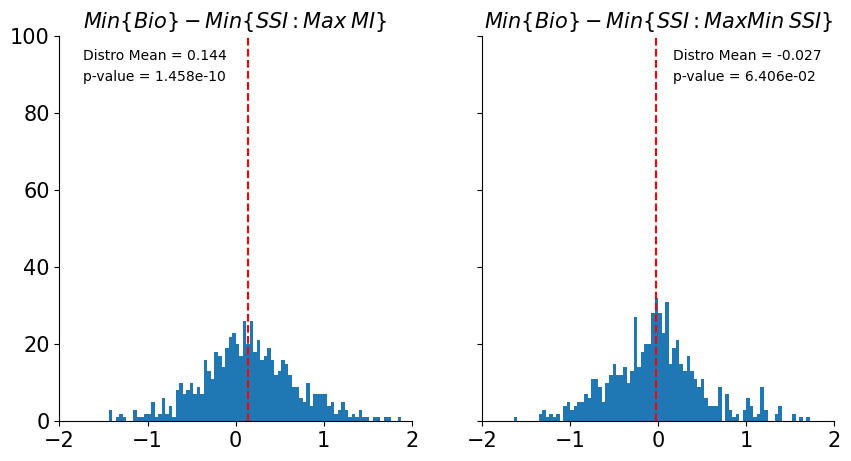

In [89]:
import random
from scipy.stats import wilcoxon

stim = np.arange(0,360,2)
first_idx = 0
last_idx = -1
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
maxMI_idx = np.argmax(data_dict['MI'])
maxMinSSI_idx = np.argmax(data_dict['minSSI'])


bio_ssi_mins = data_dict['all_ssis'][:,bio_idx,:].min(axis = 1)
maxMI_ssi_mins = data_dict['all_ssis'][:,maxMI_idx,:].min(axis = 1)
maxMin_ssi_mins = data_dict['all_ssis'][:,maxMinSSI_idx,:].min(axis = 1)


np.random.shuffle(maxMI_ssi_mins)
np.random.shuffle(maxMin_ssi_mins)

print('Mean of BIOLOGICAL QUADRUPLET MINIMA: ',np.mean(bio_ssi_mins))
print('Mean of MAXMIN QUADRUPLET MINIMA: ',np.mean(maxMin_ssi_mins))


bio_vs_maxMI_minima_diffs = bio_ssi_mins- maxMI_ssi_mins
bio_vs_maxMin_minima_diffs = bio_ssi_mins- maxMin_ssi_mins


bio_vs_maxMin_wilcoxon = wilcoxon(bio_vs_maxMin_minima_diffs)[1]
bio_vs_maxMI_wilcoxon = wilcoxon(bio_vs_maxMI_minima_diffs)[1]


from scipy.stats import wilcoxon
fig = plt.figure(figsize = (10,5))
gs = gridspec.GridSpec(1,2)
ax = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])

ax.set_title(r'$Min\{Bio\} - Min\{SSI : Max\:MI\}$', size = 15)
ax.hist(bio_vs_maxMI_minima_diffs, range = (-2,2),bins = 100)

bio_vs_maxMI_minima_diffs_mean = np.around(np.mean(bio_vs_maxMI_minima_diffs),3)
ax.axvline(bio_vs_maxMI_minima_diffs_mean, linestyle = 'dashed', color = 'red', label = f'Distro Mean = {bio_vs_maxMI_minima_diffs_mean}')
ax.scatter([0],[0], s=0, label = f'p-value = {bio_vs_maxMI_wilcoxon:.3e}')

ax.legend(handlelength = 0, frameon = 0)
ax.set_xlim(-2,2)
ax.set_ylim(0,90)
ax.set_xticks(np.arange(-2,2.1,1))
ax.set_yticks(np.arange(0,101,20))
ax.set_yticklabels(np.arange(0,101,20), size = 15)
ax.tick_params('both', labelsize = 15)


ax1.tick_params('both', labelsize = 15)
ax1.set_title(r'$Min\{Bio\} - Min\{SSI : MaxMin\:SSI\}$', size = 15)
ax1.hist(bio_vs_maxMin_minima_diffs, range = (-2,2),bins = 100)

bio_vs_maxMin_minima_diffs_mean = np.around(np.mean(bio_vs_maxMin_minima_diffs),3)



print(f'{bio_vs_maxMin_wilcoxon:.3e}')

ax1.axvline(np.mean(bio_vs_maxMin_minima_diffs), linestyle = 'dashed', color = 'red', label = f'Distro Mean = {bio_vs_maxMin_minima_diffs_mean}')
ax1.scatter([0],[0], s=0, label = f'p-value = {bio_vs_maxMin_wilcoxon:.3e}')


ax1.legend(handlelength = 0, frameon = 0, fontsize = 10)
ax1.set_xlim(-2,2)
ax1.set_ylim(0,90)
ax1.set_xticks(np.arange(-2,2.1,1))
ax1.set_yticks(np.arange(0,101,20))
ax1.set_yticklabels([])

# plt.savefig(main_dir+f'Delta Minima comparison_shuffled.pdf', bbox_inches = 'tight')


Mean of BIOLOGICAL QUADRUPLET MINIMA:  3.356256637147943
Mean of MAXMIN QUADRUPLET MINIMA:  3.481860834228954
1.056e-06


[Text(0, 0, ''),
 Text(0, 40, ''),
 Text(0, 80, ''),
 Text(0, 120, ''),
 Text(0, 160, ''),
 Text(0, 200, '')]

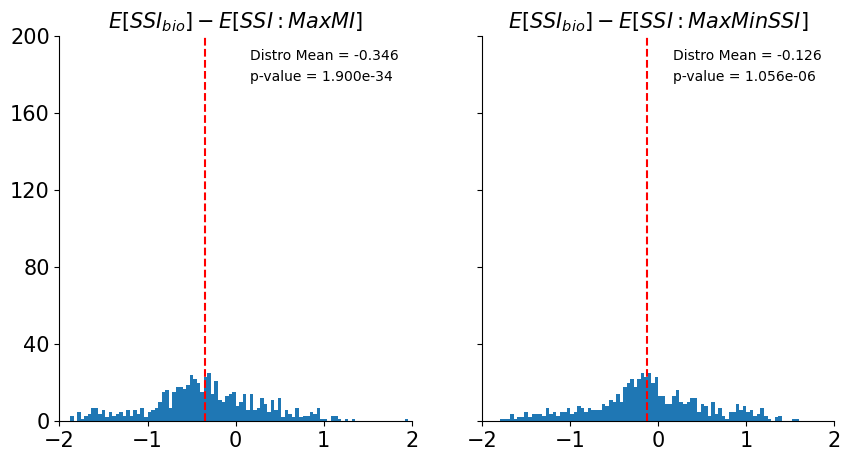

In [90]:
bio_ssi_mins = data_dict['all_ssis'][:,bio_idx,:].mean(axis = 1)
maxMI_ssi_mins = data_dict['all_ssis'][:,maxMI_idx,:].mean(axis = 1)
maxMin_ssi_mins = data_dict['all_ssis'][:,maxMinSSI_idx,:].mean(axis = 1)

np.random.shuffle(maxMI_ssi_mins)
np.random.shuffle(maxMin_ssi_mins)


print('Mean of BIOLOGICAL QUADRUPLET MINIMA: ',np.mean(bio_ssi_mins))
print('Mean of MAXMIN QUADRUPLET MINIMA: ',np.mean(maxMin_ssi_mins))


bio_vs_maxMI_minima_diffs = bio_ssi_mins-maxMI_ssi_mins
bio_vs_maxMin_minima_diffs = bio_ssi_mins-maxMin_ssi_mins


bio_vs_maxMin_wilcoxon = wilcoxon(bio_vs_maxMin_minima_diffs)[1]
bio_vs_maxMI_wilcoxon = wilcoxon(bio_vs_maxMI_minima_diffs)[1]


from scipy.stats import wilcoxon
fig = plt.figure(figsize = (10,5))
gs = gridspec.GridSpec(1,2)
ax = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])

ax.set_title(r'$E[SSI_{bio}] - E[SSI : Max MI]$', size = 15)
ax.hist(bio_vs_maxMI_minima_diffs, range = (-2,2),bins = 100)

bio_vs_maxMI_minima_diffs_mean = np.around(np.mean(bio_vs_maxMI_minima_diffs),3)
ax.axvline(bio_vs_maxMI_minima_diffs_mean, linestyle = 'dashed', color = 'red', label = f'Distro Mean = {bio_vs_maxMI_minima_diffs_mean}')
ax.scatter([0],[0], s=0, label = f'p-value = {bio_vs_maxMI_wilcoxon:.3e}')

ax.legend(handlelength = 0, frameon = 0)
ax.set_xlim(-2,2)
ax.set_ylim(0,200)
ax.set_xticks(np.arange(-2,2.1,1))
ax.set_yticks(np.arange(0,201,40))
ax.set_yticklabels(np.arange(0,201,40), size = 15)
ax.tick_params('both', labelsize = 15)


ax1.tick_params('both', labelsize = 15)
ax1.set_title(r'$E[SSI_{bio}] - E[SSI : Max Min SSI]$', size = 15)
ax1.hist(bio_vs_maxMin_minima_diffs, range = (-2,2),bins = 100)

bio_vs_maxMin_minima_diffs_mean = np.around(np.mean(bio_vs_maxMin_minima_diffs),3)



print(f'{bio_vs_maxMin_wilcoxon:.3e}')

ax1.axvline(np.mean(bio_vs_maxMin_minima_diffs), linestyle = 'dashed', color = 'red', label = f'Distro Mean = {bio_vs_maxMin_minima_diffs_mean}')
ax1.scatter([0],[0], s=0, label = f'p-value = {bio_vs_maxMin_wilcoxon:.3e}')


ax1.legend(handlelength = 0, frameon = 0, fontsize = 10)
ax1.set_xlim(-2,2)
ax1.set_ylim(0,200)
ax1.set_xticks(np.arange(-2,2.1,1))
ax1.set_yticks(np.arange(0,201,40))
ax1.set_yticklabels([])

# plt.savefig(main_dir+f'Delta Means comparison_shuffled.pdf', bbox_inches = 'tight')
